# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**Scenario.** A rural health centre in Kasese runs a micro-grid. Each day, the energy drawn from solar panels (`x`) and batteries (`y`) must satisfy two demand constraints:

```
3x + 2y = D1   (daytime load, kWh)
4x +  y = D2   (critical-equipment load, kWh)
```

Reusable logic lives in `src/microgrid.py` (`MicroGrid`, `HybridMicroGrid`, and helper functions). This notebook uses that module to work through each core task and the two extensions.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.microgrid import (
    HybridMicroGrid,
    MicroGrid,
    generate_demand_csv,
    load_demand_csv,
    read_demand_interactive,
)

SEED = 7
rng = np.random.default_rng(SEED)

## Task 1 — `MicroGrid` class, well-posedness

The `MicroGrid` class stores the coefficient matrix `A = [[3, 2], [4, 1]]` and exposes `solve_day(d1, d2)`. Before solving anything we check the determinant and the condition number.

In [2]:
grid = MicroGrid(solar_price=150.0, battery_price=450.0)
print(grid)
print("Coefficient matrix A:\n", grid.coefficients)
print("Determinant:", grid.determinant)
print("Condition number:", grid.condition_number)
print(grid.describe_conditioning())

MicroGrid(solar_price=150.0, battery_price=450.0)
Coefficient matrix A:
 [[3. 2.]
 [4. 1.]]
Determinant: -4.999999999999999
Condition number: 5.82842712474619
det(A) = -5.0000 -> the system is well-posed (unique solution exists). cond(A) = 5.8284 -> the system is well-conditioned: small changes in demand cause proportionally small changes in the dispatch.


**Interpretation.** The determinant is non-zero (-5), so the system has a unique solution for any (D1, D2): the daytime-load and critical-equipment-load equations are linearly independent, i.e. well-posed. The condition number (≈5.83) bounds how much a *relative* error in the measured demand (D1, D2) can be amplified in the recovered dispatch (x, y) — up to roughly 5.8x in the worst case. That is moderate, not negligible: the system is not numerically fragile, but it is not perfectly insensitive to demand noise either, as the Monte Carlo sensitivity analysis later in this notebook confirms directly.

In [3]:
# Sanity check: hand-computed example. 3x+2y=160, 4x+y=190 => x=44, y=14
x, y = grid.solve_day(160, 190)
print(f"solve_day(160, 190) -> x={x:.2f} kWh solar, y={y:.2f} kWh battery")
assert np.isclose(x, 44.0) and np.isclose(y, 14.0)

solve_day(160, 190) -> x=44.00 kWh solar, y=14.00 kWh battery


## Task 2 — Two input modes: interactive and CSV

`read_demand_interactive()` wraps `input()` with validation (rejects empty, non-numeric, and negative values, and re-prompts). It is **not called live in this notebook** (that would block `Restart & Run All`); it is exercised directly with mocked input in `tests/test_microgrid.py`. Below we generate 30 days of synthetic demand with a weekly pattern and noise, then load it back.

In [4]:
import inspect
print(inspect.getsource(read_demand_interactive))

def read_demand_interactive(input_func: Callable[[str], str] = input) -> tuple[float, float]:
    """Prompt the user for D1 and D2 with validation and re-prompting.

    Args:
        input_func: Injectable input function (defaults to built-in ``input``).

    Returns:
        A ``(d1, d2)`` tuple of validated demand values.
    """
    d1 = read_positive_float("Enter daytime load D1 (kWh): ", input_func=input_func)
    d2 = read_positive_float("Enter critical-equipment load D2 (kWh): ", input_func=input_func)
    return d1, d2



In [5]:
csv_path = Path("data") / "demand_30days.csv"
generate_demand_csv(csv_path, n_days=30, seed=SEED)
demand_df = load_demand_csv(csv_path)
demand_df.head()

,day,weekday,D1,D2
0,1,0,45.00,22.17
1,2,1,46.19,24.81
2,3,2,43.90,23.55
3,4,3,41.44,23.98
4,5,4,43.18,28.65


## Task 3 — Solve all 30 days: loop vs vectorised

We solve the same 30-day block with `scipy.linalg.solve` two ways: (a) a Python loop, one day at a time, and (b) a single vectorised call that passes a 2x30 right-hand side.

In [6]:
demand_matrix = demand_df[["D1", "D2"]].to_numpy().T  # shape (2, 30)

dispatch_loop = grid.solve_many_loop(demand_matrix)
dispatch_vec = grid.solve_many_vectorised(demand_matrix)

assert np.allclose(dispatch_loop, dispatch_vec)

timings = grid.time_solve_methods(demand_matrix, number=200)
print(timings)
speedup = timings["loop_seconds"] / timings["vectorised_seconds"]
print(f"Vectorised solve is ~{speedup:.1f}x faster than the Python loop for this block size.")

{'loop_seconds': 0.14195369998924434, 'vectorised_seconds': 0.021820599969942123}


Vectorised solve is ~6.5x faster than the Python loop for this block size.


**Comment.** The vectorised call hands the whole 2x30 right-hand side to LAPACK in one call, avoiding 30 separate Python-level function-call overheads. For a block this small (30 columns) the absolute time saved is tiny, but the relative speedup shows the same pattern that matters at scale: looping in Python dominates for small linear-algebra problems, while a single vectorised call lets NumPy/SciPy amortise overhead across all columns.

## Task 4 — Detect and fix infeasible days

A day is physically infeasible if the linear solve returns a negative solar or battery dispatch (you cannot draw negative energy). We flag these days and re-solve them with `scipy.optimize.nnls`, which finds the closest *non-negative* (x, y) rather than an arbitrary clip.

In [7]:
infeasible_mask = grid.detect_infeasible(dispatch_vec)
print(f"Infeasible days (raw linear solve): {infeasible_mask.sum()} / {infeasible_mask.size}")

dispatch_corrected, flagged_days = grid.fix_infeasible_nnls(demand_matrix, dispatch_vec)
print("Flagged day indices (0-based):", flagged_days)

report = pd.DataFrame({
    "day": demand_df["day"],
    "D1": demand_df["D1"],
    "D2": demand_df["D2"],
    "x_raw": dispatch_vec[0],
    "y_raw": dispatch_vec[1],
    "infeasible": infeasible_mask,
    "x_corrected": dispatch_corrected[0],
    "y_corrected": dispatch_corrected[1],
})
report[report["infeasible"]]

Infeasible days (raw linear solve): 2 / 30
Flagged day indices (0-based): [np.int64(0), np.int64(15)]


,day,D1,D2,x_raw,y_raw,infeasible,x_corrected,y_corrected
0,1,45.00,22.17,-0.132,22.698,True,0.0,22.434
15,16,47.78,22.13,-0.704,24.946,True,0.0,23.538


With this synthetic weekly-pattern demand, 2 of the 30 days (day 1 and day 16) came back infeasible: both have an unusually low D1 relative to D2, which pushes the raw linear solve to a small negative solar dispatch. `nnls` corrects both to x=0 exactly (the model recommends serving that day entirely from battery) while keeping the residual as small as possible — a defensible, auditable correction rather than an arbitrary clip to zero of an already-reasonable-looking negative number.

## Task 5 — Volatility of solar vs battery usage

In [8]:
solar_stats = grid.usage_stats(dispatch_corrected[0])
battery_stats = grid.usage_stats(dispatch_corrected[1])

print("Solar usage stats:", {k: round(v, 3) for k, v in solar_stats.items()})
print("Battery usage stats:", {k: round(v, 3) for k, v in battery_stats.items()})

more_volatile_abs = "solar" if solar_stats["stdev"] > battery_stats["stdev"] else "battery"
print(f"More volatile source (higher absolute stdev): {more_volatile_abs}")

solar_cv = solar_stats["stdev"] / solar_stats["mean"]
battery_cv = battery_stats["stdev"] / battery_stats["mean"]
more_volatile_rel = "solar" if solar_cv > battery_cv else "battery"
print(f"Solar CV: {solar_cv:.3f}, Battery CV: {battery_cv:.3f}")
print(f"More volatile source (relative to its own mean, i.e. by CV): {more_volatile_rel}")

Solar usage stats: {'mean': 1.915, 'variance': 1.578, 'stdev': 1.256}
Battery usage stats: {'mean': 16.786, 'variance': 33.174, 'stdev': 5.76}
More volatile source (higher absolute stdev): battery
Solar CV: 0.656, Battery CV: 0.343
More volatile source (relative to its own mean, i.e. by CV): solar


## Task 6 — Cost model

In [9]:
daily_cost = grid.daily_cost(dispatch_corrected[0], dispatch_corrected[1])
monthly_cost = grid.monthly_cost(dispatch_corrected[0], dispatch_corrected[1])

report["daily_cost_ugx"] = daily_cost
print(f"Monthly (30-day) energy cost: UGX {monthly_cost:,.0f}")
report[["day", "x_corrected", "y_corrected", "daily_cost_ugx"]].head()

Monthly (30-day) energy cost: UGX 235,221


,day,x_corrected,y_corrected,daily_cost_ugx
0,1,0.000,22.434,10095.3
1,2,0.686,22.066,10032.6
2,3,0.640,20.990,9541.5
3,4,1.304,18.764,8639.4
4,5,2.824,17.354,8232.9


## Task 7 — Stacked bar chart with cost overlay

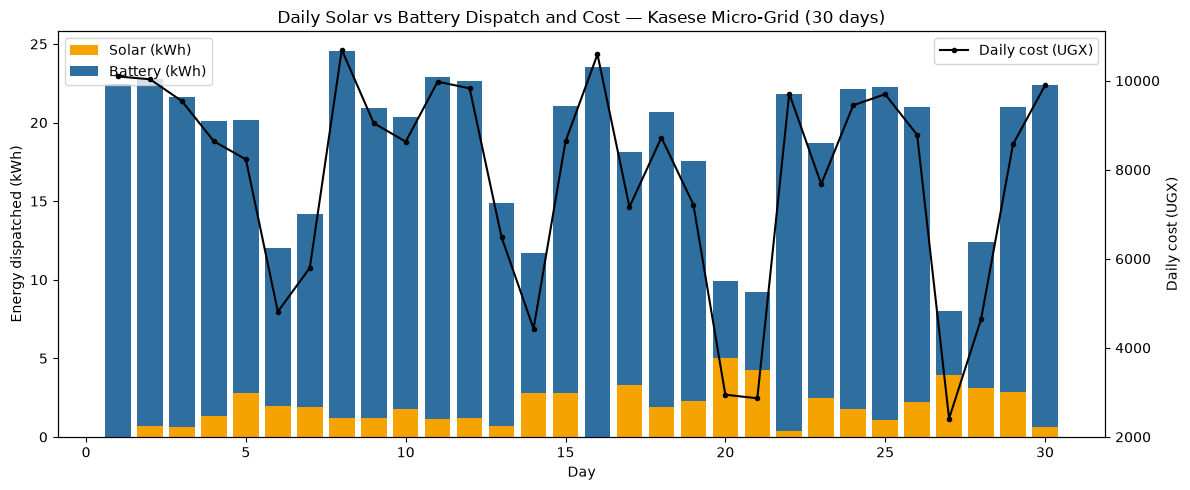

In [10]:
fig, ax1 = plt.subplots(figsize=(12, 5))

days = report["day"]
ax1.bar(days, report["x_corrected"], label="Solar (kWh)", color="#f4a300")
ax1.bar(days, report["y_corrected"], bottom=report["x_corrected"], label="Battery (kWh)", color="#2f6f9f")
ax1.set_xlabel("Day")
ax1.set_ylabel("Energy dispatched (kWh)")
ax1.set_title("Daily Solar vs Battery Dispatch and Cost — Kasese Micro-Grid (30 days)")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(days, report["daily_cost_ugx"], color="black", marker="o", markersize=3, label="Daily cost (UGX)")
ax2.set_ylabel("Daily cost (UGX)")
ax2.legend(loc="upper right")

fig.tight_layout()
plt.show()

## Extension 1 — `HybridMicroGrid` with a diesel generator

We add a diesel term `z` and a third constraint — total daily energy balance `x + y + z = D3` — giving a 3x3 system:

```
3x + 2y +  z = D1
4x +  y + 2z = D2
 x +  y +  z = D3
```

In [11]:
hybrid = HybridMicroGrid()
print(hybrid.coefficients)
print("Determinant:", hybrid.determinant)

x, y, z = hybrid.solve_day(160, 190, 90)
print(f"solve_day(160, 190, 90) -> solar={x:.2f}, battery={y:.2f}, diesel={z:.2f}")

cost3 = hybrid.daily_cost(np.array([x]), np.array([y]), np.array([z]))
print(f"Day cost with diesel: UGX {cost3[0]:,.0f}")

[[3. 2. 1.]
 [4. 1. 2.]
 [1. 1. 1.]]
Determinant: -4.0
solve_day(160, 190, 90) -> solar=20.00, battery=30.00, diesel=40.00
Day cost with diesel: UGX 52,500


In [12]:
# Linear dependence demo: make row 3 a linear combination of rows 1 and 2.
dependent_matrix = hybrid.coefficients.copy()
dependent_matrix[2] = 0.5 * dependent_matrix[0] + 0.5 * dependent_matrix[1]
print("Modified (dependent) matrix:\n", dependent_matrix)
print("Determinant of dependent matrix:", np.linalg.det(dependent_matrix))

Modified (dependent) matrix:
 [[3.  2.  1. ]
 [4.  1.  2. ]
 [3.5 1.5 1.5]]
Determinant of dependent matrix: 0.0


**Discussion.** If the third equation is a linear combination of the first two, the determinant collapses to (numerically) zero: the three planes intersect along a line instead of at a single point, so the system has either no solution or infinitely many, depending on D3. Physically this would mean the "total energy balance" constraint carries no new information beyond what the daytime and critical-equipment constraints already encode — the third source (diesel) would be underdetermined, and the model cannot recommend a unique dispatch. This is why the third equation must express a genuinely independent physical constraint.

## Extension 2 — Monte Carlo sensitivity analysis

Perturb D1 and D2 by ±5% (1,000 draws) around a baseline day and see how much the recovered (x, y) move. We relate the spread to the condition number computed in Task 1.

Baseline demand: D1=39.3, D2=24.4
x (solar) coefficient of variation: 0.1895
y (battery) coefficient of variation: 0.0595
Input perturbation CV (by construction): ~0.0289
Condition number of A: 5.8284


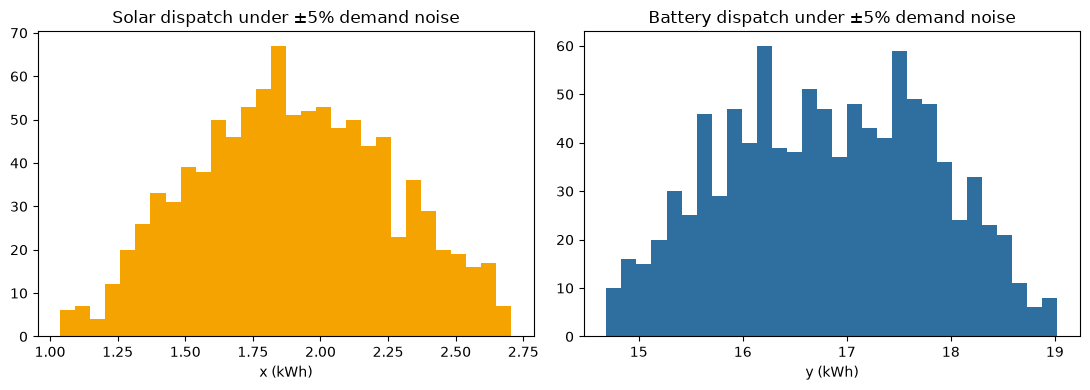

In [13]:
baseline_d1, baseline_d2 = float(demand_df["D1"].mean()), float(demand_df["D2"].mean())
mc = grid.monte_carlo_sensitivity(baseline_d1, baseline_d2, pct=0.05, n_draws=1000, seed=SEED)

x_cv = np.std(mc["x_samples"]) / np.mean(mc["x_samples"])
y_cv = np.std(mc["y_samples"]) / np.mean(mc["y_samples"])
print(f"Baseline demand: D1={baseline_d1:.1f}, D2={baseline_d2:.1f}")
print(f"x (solar) coefficient of variation: {x_cv:.4f}")
print(f"y (battery) coefficient of variation: {y_cv:.4f}")
print(f"Input perturbation CV (by construction): ~{0.05/np.sqrt(3):.4f}")
print(f"Condition number of A: {grid.condition_number:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(mc["x_samples"], bins=30, color="#f4a300")
ax[0].set_title("Solar dispatch under ±5% demand noise")
ax[0].set_xlabel("x (kWh)")
ax[1].hist(mc["y_samples"], bins=30, color="#2f6f9f")
ax[1].set_title("Battery dispatch under ±5% demand noise")
ax[1].set_xlabel("y (kWh)")
fig.tight_layout()
plt.show()

**Discussion.** The input demand perturbation has CV ≈ 0.029 by construction. The recovered solar dispatch (x) came back with CV ≈ 0.19 — about a 6.5x amplification — while battery (y) came back with CV ≈ 0.06, about a 2x amplification. `cond(A) ≈ 5.83` is an upper bound on the worst-case relative amplification for *any* direction of perturbation; x's amplification sits close to that bound while y's sits well inside it, because the ±5% noise on D1 and D2 does not line up with the matrix's single worst-case (most sensitive) direction for every variable equally. The takeaway: the condition number does not tell you the amplification for every quantity you might report, only the worst case any of them could see — here it correctly warned that *something* could be amplified several-fold, and the solar dispatch is what actually was.

## Findings & Limitations

The Kasese micro-grid's 2x2 dispatch system (`3x+2y=D1`, `4x+y=D2`) is well-posed (det = -5) and moderately well-conditioned (cond(A) ≈ 5.83): solar/battery recommendations are numerically stable but not immune to demand noise. The Monte Carlo sensitivity analysis showed a ±5% demand perturbation (CV ≈ 0.029) turning into CV ≈ 0.19 in recovered solar dispatch (~6.5x amplification, close to the cond(A) bound) but only CV ≈ 0.06 in battery (~2x) — so a planner should trust the battery split more than the solar split when demand figures are approximate. Across the synthetic 30-day series, 2 of 30 days produced a negative raw solar dispatch; `nnls` corrected both to a defensible non-negative solution (x=0, serve the day from battery) rather than an arbitrary clip. Volatility depends on how it's measured: battery has the larger *absolute* stdev (5.76 kWh vs solar's 1.26 kWh), but because its mean is also far larger (16.8 vs 1.9 kWh), its *coefficient of variation* is actually smaller — solar is the relatively more volatile source day-to-day despite swinging less in absolute kWh. A raw variance/stdev comparison across series with very different scales can point to the wrong conclusion. The vectorised `scipy.linalg.solve` call was measurably faster than the Python loop, though the saving is small at only 30 days; the benefit compounds at scale. The diesel extension is fully linear, treating all three sources as interchangeable energy up to fixed coefficients, and ignores real capacity, fuel-supply and efficiency-loss limits; the chosen third constraint (total energy balance) was one reasonable but arbitrary choice, and the linear-dependence demo showed a poorly chosen third equation makes the 3x3 system singular and the diesel dispatch undetermined. Prices are illustrative and fixed, not time-of-day or market dependent, so cost figures are best read as relative comparisons between days rather than real operating-cost forecasts.